<a href="https://colab.research.google.com/github/vinaysampath30-lgtm/s10-dlac/blob/main/skill4_dlac.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

VISIONPORT PERFORMANCE BENCHMARK
CPU Average Inference Time: 18.4590 ms
CUDA GPU is not available.
GPU benchmark skipped.

Benchmark Results:
CPU: 18.4590 ms


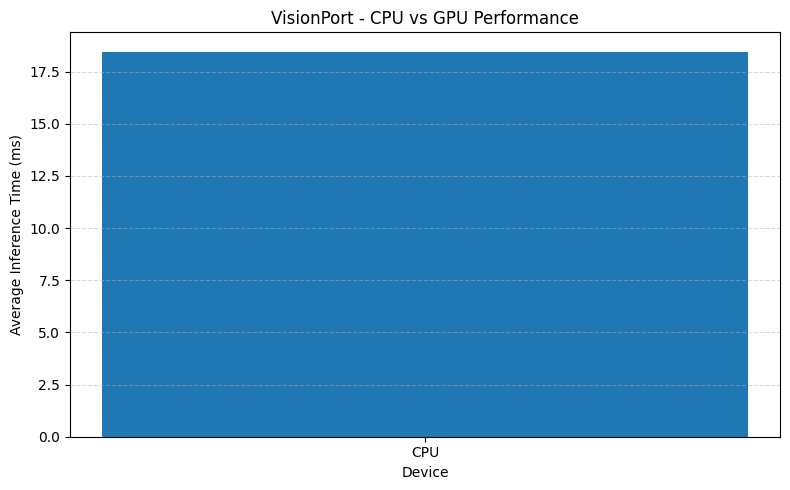


Benchmark completed successfully!


In [3]:
# ============================================================
# VISIONPORT - CNN MODEL + CPU/GPU BENCHMARK (FIXED)
# ============================================================

import time
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. DEFINE THE CNN MODEL (Fix: VisionPortCNN not defined)
# ------------------------------------------------------------

class VisionPortCNN(nn.Module):
    def __init__(self):
        super(VisionPortCNN, self).__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Linear(32, 10)

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)
        return x


# ------------------------------------------------------------
# 2. DEFINE BENCHMARK FUNCTION
# ------------------------------------------------------------

def benchmark(device, iterations=20):

    benchmark_model = VisionPortCNN().to(device)
    benchmark_model.eval()

    data = torch.randn(8, 3, 64, 64).to(device)

    # Warm-up
    with torch.no_grad():
        for _ in range(5):
            benchmark_model(data)

        if device.type == "cuda":
            torch.cuda.synchronize()

        # Start timing
        start = time.perf_counter()

        for _ in range(iterations):
            benchmark_model(data)

        if device.type == "cuda":
            torch.cuda.synchronize()

        end = time.perf_counter()

    average_time = ((end - start) / iterations) * 1000

    return average_time


# ------------------------------------------------------------
# 3. CPU BENCHMARK
# ------------------------------------------------------------

cpu_time = benchmark(torch.device("cpu"))

times = {"CPU": cpu_time}

print("=" * 50)
print("VISIONPORT PERFORMANCE BENCHMARK")
print("=" * 50)

print(f"CPU Average Inference Time: {cpu_time:.4f} ms")


# ------------------------------------------------------------
# 4. GPU BENCHMARK
# ------------------------------------------------------------

if torch.cuda.is_available():

    gpu_time = benchmark(torch.device("cuda"))

    times["GPU"] = gpu_time

    print(f"GPU Average Inference Time: {gpu_time:.4f} ms")

    speedup = cpu_time / gpu_time

    print(f"GPU Speedup: {speedup:.2f}x")

else:

    print("CUDA GPU is not available.")
    print("GPU benchmark skipped.")


# ------------------------------------------------------------
# 5. DISPLAY RESULTS
# ------------------------------------------------------------

print("\nBenchmark Results:")
for device_name, execution_time in times.items():
    print(f"{device_name}: {execution_time:.4f} ms")


# ------------------------------------------------------------
# 6. PERFORMANCE GRAPH
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.bar(times.keys(), times.values())

plt.title("VisionPort - CPU vs GPU Performance")
plt.xlabel("Device")
plt.ylabel("Average Inference Time (ms)")

plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

print("\nBenchmark completed successfully!")